In [97]:
import matplotlib.pyplot as plt
import numpy as np
from Boosting import AdaBoost_maison
from sklearn.datasets import fetch_openml
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.utils import resample
from xgboost import DMatrix, XGBClassifier


In [98]:
# Load MNIST data
X_mnist, y_mnist = fetch_openml('mnist_784', return_X_y=True, as_frame=False)
y_mnist = y_mnist.astype(np.int8)  # Convert labels to integers

In [99]:
# Split the data into training and test sets
split_size = int(X_mnist.shape[0] * 6/7)
X_train, y_train = X_mnist[:split_size]/255., y_mnist[:split_size]
X_test, y_test = X_mnist[split_size:]/255., y_mnist[split_size:]

In [31]:
mod1 = AdaBoost_maison(n_estimators=100, max_depth=3)

mod1.fit(X_train, y_train)
yhat_1 = mod1.predict(X_test)

In [100]:
mod_xgb = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, objective='multi:softmax', num_class=10)

mod_xgb.fit(X_train, y_train)
yhat = mod_xgb.predict_proba(X_test)

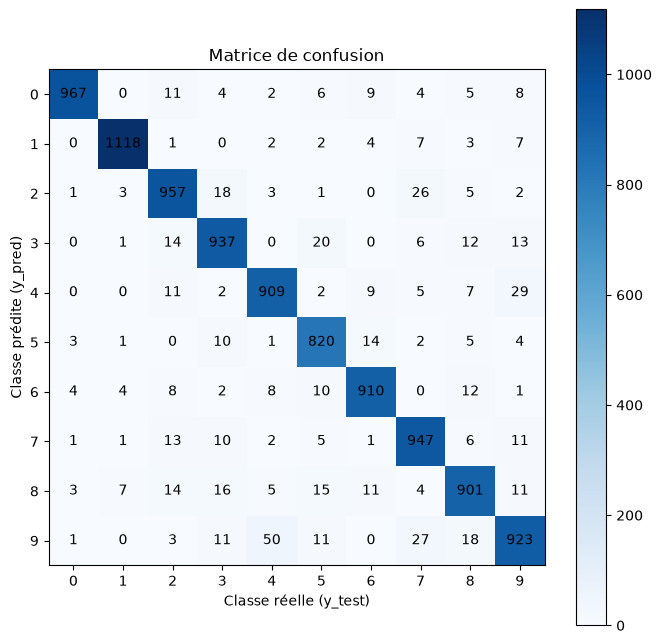

In [101]:
y_pred = yhat.argmax(axis=1)

confusion = np.zeros((10, 10), dtype=int)
np.add.at(confusion, (y_pred, y_test), 1)

plt.figure(figsize=(8, 8))
plt.imshow(confusion, cmap="Blues")
plt.colorbar()
plt.xticks(range(10), range(10))
plt.yticks(range(10), range(10))
plt.xlabel("Classe réelle (y_test)")
plt.ylabel("Classe prédite (y_pred)")
plt.title("Matrice de confusion")

for i in range(10):
    for j in range(10):
        plt.text(j, i, confusion[i, j], ha="center", va="center")

plt.show()


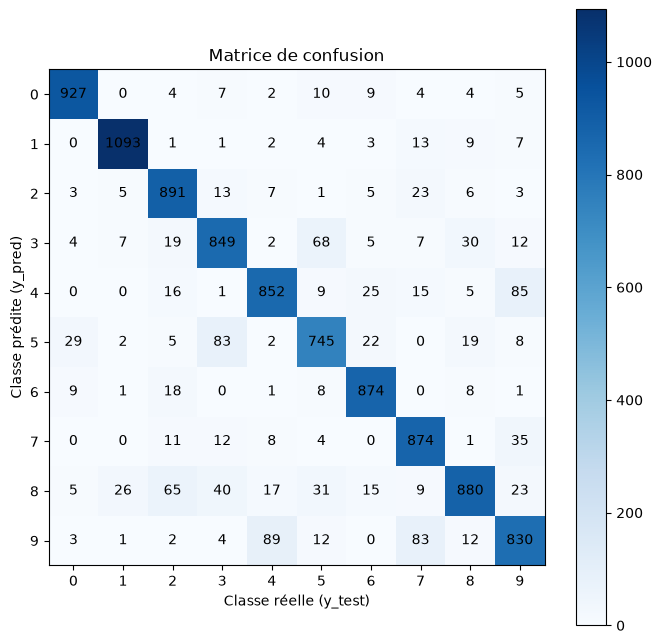

In [34]:
y_pred = yhat_1

confusion = np.zeros((10, 10), dtype=int)
np.add.at(confusion, (y_pred, y_test), 1)

plt.figure(figsize=(8, 8))
plt.imshow(confusion, cmap="Blues")
plt.colorbar()
plt.xticks(range(10), range(10))
plt.yticks(range(10), range(10))
plt.xlabel("Classe réelle (y_test)")
plt.ylabel("Classe prédite (y_pred)")
plt.title("Matrice de confusion")

for i in range(10):
    for j in range(10):
        plt.text(j, i, confusion[i, j], ha="center", va="center")

plt.show()


In [ ]:
# Split the data into training and test sets
w = []
for k in range(10):
    split_size = int(X_mnist.shape[0] / 10)
    X_train, y_train = X_mnist[:split_size]/255., y_mnist[:split_size]
    X_test, y_test = X_mnist[split_size:]/255., y_mnist[split_size:]

    mod = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, objective='multi:softmax', num_class=10)

    mod.fit(X_train, y_train)
    yhat = mod.predict_proba(X_test)

    y_pred = yhat.argmax(axis=1)

    w.append(mod.feature_importances_)


In [ ]:
w_temp = w.copy()
w_temp.mean(axis=0).reshape(28, 28)

confusion = np.zeros((10, 10), dtype=int)
np.add.at(confusion, (y_pred, y_test), 1)

plt.figure(figsize=(8, 8))
plt.imshow(confusion, cmap="Blues")
plt.colorbar()
plt.xticks(range(10), range(10))
plt.yticks(range(10), range(10))
plt.xlabel("Classe réelle (y_test)")
plt.ylabel("Classe prédite (y_pred)")
plt.title("Matrice de confusion")

for i in range(10):
    for j in range(10):
        plt.text(j, i, confusion[i, j], ha="center", va="center")

plt.show()


In [38]:
X_train, X_test, y_train, y_test = train_test_split(X_mnist, y_mnist, test_size=0.2, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
r = cross_validate(mod, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)


In [40]:
print(r['test_score'])

[0.92964286 0.93223214 0.93964286 0.933125   0.93348214]


Test d'hyperparamètres  
Relanncer sur données entières et avec plus d'hyper-paramètres + Tester GridSearchCV et Optuna

In [ ]:
X_bis, y_bis = resample(X_mnist, y_mnist, n_samples=1000, random_state=42)
# X_train, X_test, y_train, y_test = train_test_split(X_mnist, y_mnist, test_size=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X_bis, y_bis, test_size=0.2, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

N_ESTI = [20,50, 150]
DEPTH = [1, 3, 5]
LR = [0.01, 0.1, 0.5]

R = np.zeros((len(N_ESTI), len(DEPTH), len(LR)))

for a, n_esti in enumerate(N_ESTI):
    for b, depth in enumerate(DEPTH):
        for c, lr in enumerate(LR):
            mod = XGBClassifier(n_estimators=n_esti, max_depth=depth, learning_rate=lr, objective='multi:softmax', num_class=10)
            r = cross_validate(mod, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
            print(a, b, c, r['test_score'].mean())
            R[a, b, c] = r['test_score'].mean()


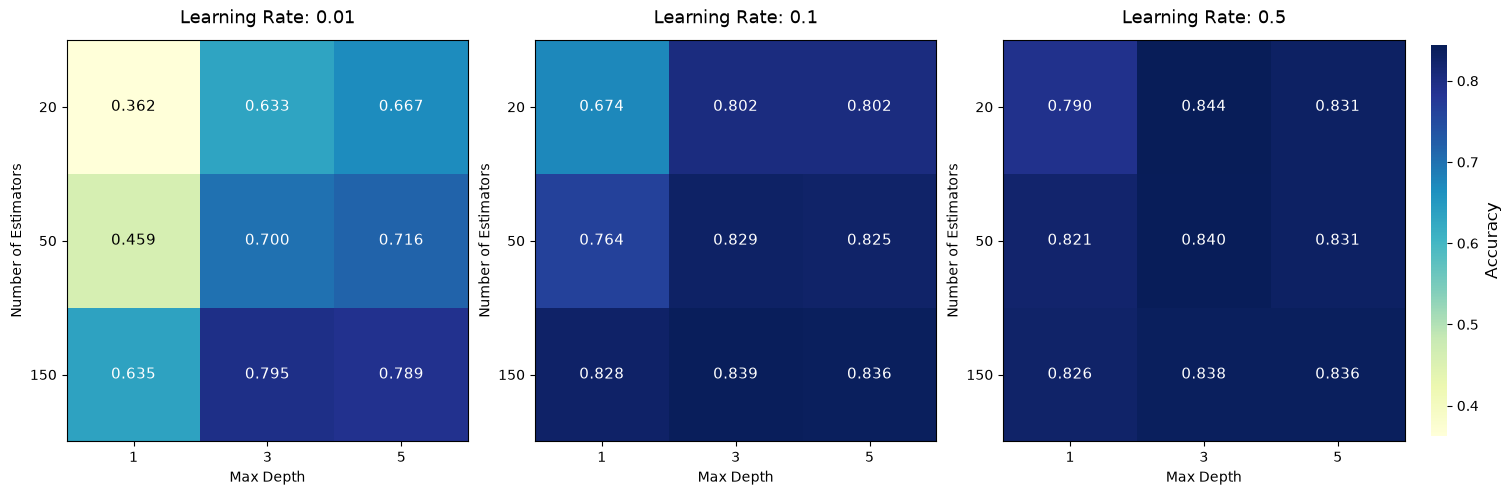

In [64]:
fig, ax = plt.subplots(1, len(LR), figsize=(15, 5), constrained_layout=True)
vmin, vmax = R.min(), R.max()

for i, lr in enumerate(LR):
    im = ax[i].imshow(R[:, :, i], cmap='YlGnBu', vmin=vmin, vmax=vmax)
    ax[i].set_title(f'Learning Rate: {lr}', fontsize=13, pad=12)
    ax[i].set_xticks(range(len(DEPTH)), DEPTH)
    ax[i].set_yticks(range(len(N_ESTI)), N_ESTI)
    ax[i].set_xlabel('Max Depth')
    ax[i].set_ylabel('Number of Estimators')

    for j in range(len(N_ESTI)):
        for k in range(len(DEPTH)):
            value = R[j, k, i]
            ax[i].text(k, j, f'{value:.3f}', ha='center', va='center', fontsize=11,
                       color='white' if value > (vmin + vmax) / 2 else 'black')

cbar = fig.colorbar(im, ax=ax, shrink=0.8, aspect=25, pad=0.02)
cbar.set_label('Accuracy', fontsize=12)
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=10)

Regarder des classes binaires

In [89]:
c3vs8_idx = np.where((y_mnist == 3) | (y_mnist == 8))[0]
X_c3vs8 = X_mnist[c3vs8_idx]
y_c3vs8 = y_mnist[c3vs8_idx]
y_c3vs8 = np.where(y_c3vs8 == 3, 0, 1)  # Convert labels to binary (0 for 3, 1 for 8)

X1_train, X1_test, y1_train, y1_test = train_test_split(X_c3vs8, y_c3vs8, test_size=0.2, random_state=42)

mod = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, objective='binary:logistic')
mod.fit(X_c3vs8, y_c3vs8)
yhat_2 = mod.predict(X1_test)

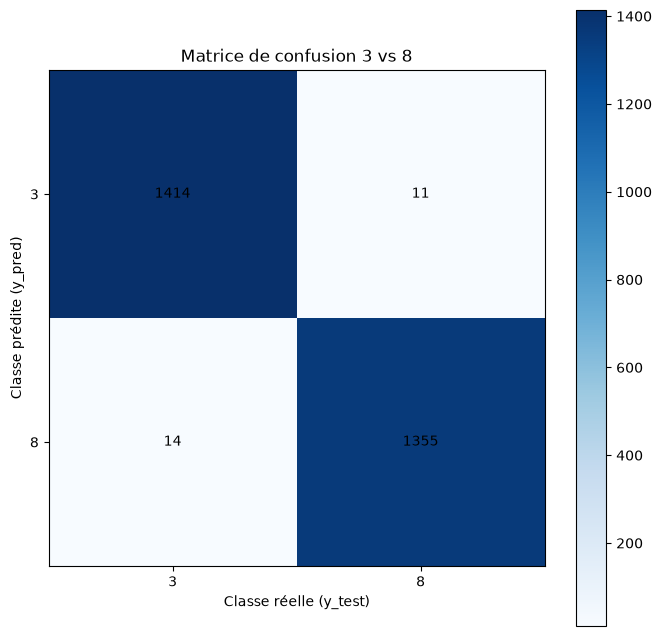

In [91]:
n = len(np.unique(yhat_2))

labels = [3, 8]  # Labels for the classes

confusion = np.zeros((n,n), dtype=int)

np.add.at(confusion, (yhat_2, y1_test), 1)

plt.figure(figsize=(8, 8))
plt.imshow(confusion, cmap="Blues")
plt.colorbar()

plt.xticks(range(n), labels)
plt.yticks(range(n), labels)

plt.xlabel("Classe réelle (y_test)")
plt.ylabel("Classe prédite (y_pred)")
plt.title("Matrice de confusion 3 vs 8")

for i in range(n):
    for j in range(n):
        plt.text(j, i, confusion[i, j], ha="center", va="center")

plt.show()


In [105]:
print(mod_xgb.feature_importances_.shape)

(784,)


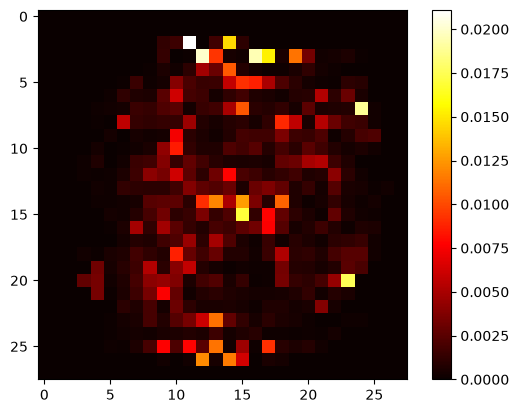

In [102]:
W = mod_xgb.feature_importances_.reshape(28, 28)
plt.imshow(W, cmap='hot', interpolation='nearest')
plt.colorbar()

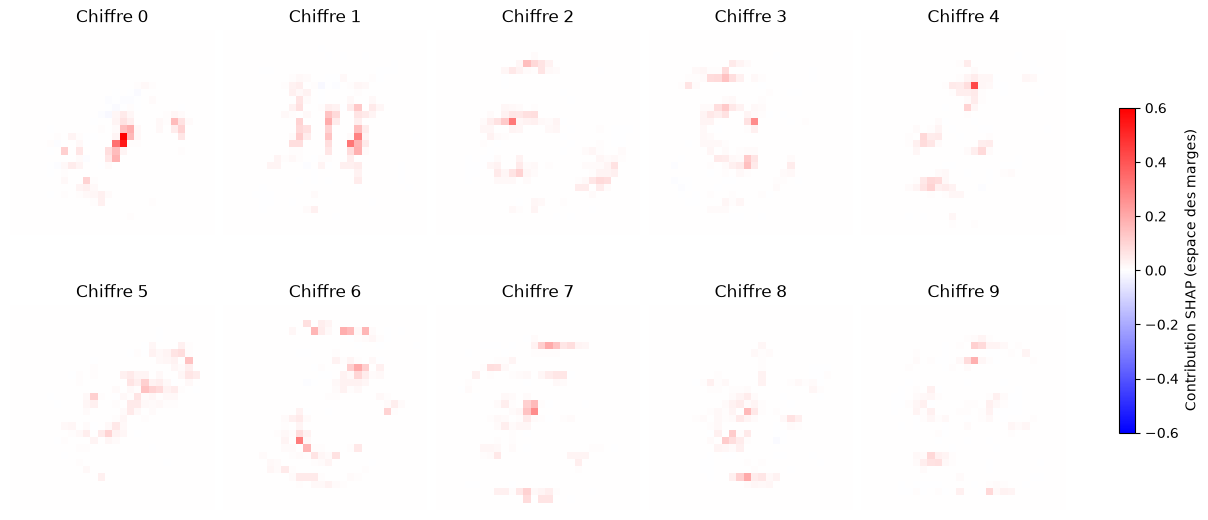

In [109]:
import shap
import matplotlib.pyplot as plt

# X_test et y_test ont été écrasés par les cellules de CV : on reconstruit le jeu de test hold-out de la cellule 2
split_size = int(X_mnist.shape[0] * 6/7)
X_hold, y_hold = X_mnist[split_size:]/255., y_mnist[split_size:]

# 50 images par chiffre pour limiter le temps de calcul
n_per_class = 50
idx = np.concatenate([np.where(y_hold == c)[0][:n_per_class] for c in range(10)])
X_s, y_s = X_hold[idx], y_hold[idx]

explainer = shap.TreeExplainer(mod_xgb)
sv = explainer.shap_values(X_s)
# Selon la version de shap : liste de 10 (n, 784) ou tableau (n, 784, 10) -> on force (10, n, 784)
sv = np.array(sv) if isinstance(sv, list) else np.moveaxis(sv, -1, 0)

# Carte moyenne par chiffre : valeurs SHAP de la classe d sur les images de vrai chiffre d
M = np.zeros((10, 28, 28))
for d in range(10):
    M[d] = sv[d][y_s == d].mean(axis=0).reshape(28, 28)

m = np.abs(M).max()
fig, ax = plt.subplots(2, 5, figsize=(12, 5.5), constrained_layout=True)
for d in range(10):
    im = ax.flat[d].imshow(M[d], cmap='bwr', vmin=-m, vmax=m)
    ax.flat[d].set_title(f'Chiffre {d}')
    ax.flat[d].axis('off')
fig.colorbar(im, ax=ax, shrink=0.6, label='Contribution SHAP (espace des marges)')
plt.show()


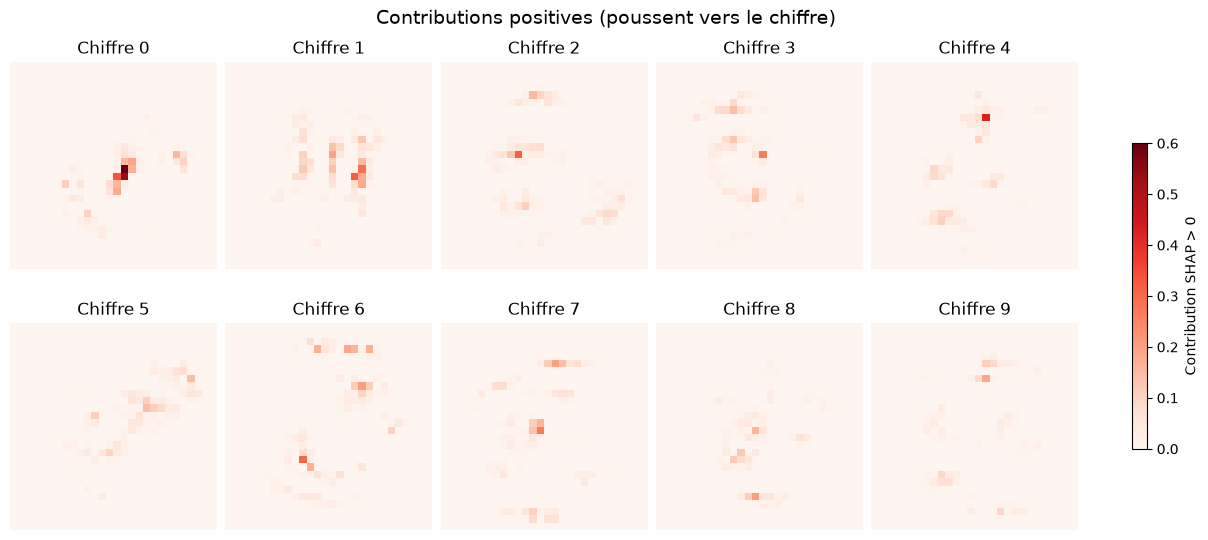

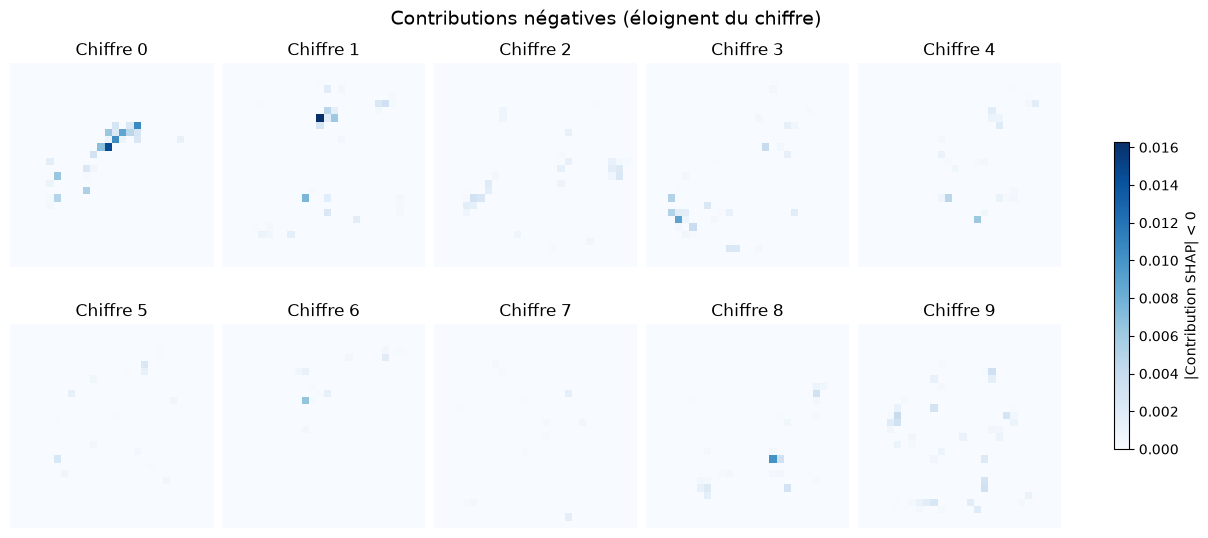

In [110]:
# Séparation des contributions positives et négatives
M_pos = np.clip(M, 0, None)
M_neg = np.clip(-M, 0, None)  # valeur absolue des contributions négatives

def plot_carte(carte, cmap, titre, label):
    vmax = carte.max()
    fig, ax = plt.subplots(2, 5, figsize=(12, 5.5), constrained_layout=True)
    for d in range(10):
        im = ax.flat[d].imshow(carte[d], cmap=cmap, vmin=0, vmax=vmax)
        ax.flat[d].set_title(f'Chiffre {d}')
        ax.flat[d].axis('off')
    fig.colorbar(im, ax=ax, shrink=0.6, label=label)
    fig.suptitle(titre, fontsize=14)
    plt.show()

plot_carte(M_pos, 'Reds', 'Contributions positives (poussent vers le chiffre)', 'Contribution SHAP > 0')
plot_carte(M_neg, 'Blues', 'Contributions négatives (éloignent du chiffre)', '|Contribution SHAP| < 0')
